In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import surprise
from surprise import accuracy

project_root = Path.cwd().resolve()
if project_root.name == "notebooks":
    project_root = project_root.parents[1]
elif project_root.name == "tarea_01":
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

In [2]:
dataset_path = Path('../dataset')
train_df = pd.read_csv(dataset_path / 'train.csv')
train_df.date = pd.to_datetime(train_df.date)

test_df = pd.read_csv(dataset_path / 'validation.csv')
test_df.date = pd.to_datetime(test_df.date)

reader = surprise.reader.Reader(rating_scale=(0,5))

train_data = surprise.Dataset.load_from_df(
    train_df[["user_id", "recipe_id", "rating"]], reader=reader
)
trainset = train_data.build_full_trainset()

test_data = surprise.Dataset.load_from_df(
    test_df[["user_id", "recipe_id", "rating"]], reader=reader
)
testset = test_data.construct_testset(
    test_data.raw_ratings
)

In [3]:
k_values = [10, 30, 50, 80]
similarity_values = ["pearson", "msd"]

item_rows = []
item_models = {}

for similarity in similarity_values:
    for k in k_values:
        model = surprise.KNNBasic(
            k=k,
            min_k=1,
            sim_options={"name": similarity, "user_based": False},
            verbose=False,
        )
        model.fit(trainset)
        predictions = model.test(testset)
        item_rows.append(
            {
                "method": "ItemKNN",
                "k_neighbors": k,
                "similarity": similarity,
                "RMSE": round(float(accuracy.rmse(predictions, verbose=False)), 4),
                "MAE": round(float(accuracy.mae(predictions, verbose=False)), 4),
            }
        )
        item_models[(k, similarity)] = model

item_results = pd.DataFrame(item_rows)
item_results.sort_values("RMSE")

,method,k_neighbors,similarity,RMSE,MAE
7,ItemKNN,80,msd,0.9108,0.4852
6,ItemKNN,50,msd,0.9115,0.4850
5,ItemKNN,30,msd,0.9131,0.4848
4,ItemKNN,10,msd,0.9269,0.4891
2,ItemKNN,50,pearson,0.9969,0.5390
3,ItemKNN,80,pearson,0.9969,0.5390
1,ItemKNN,30,pearson,0.9969,0.5390
0,ItemKNN,10,pearson,0.9974,0.5388


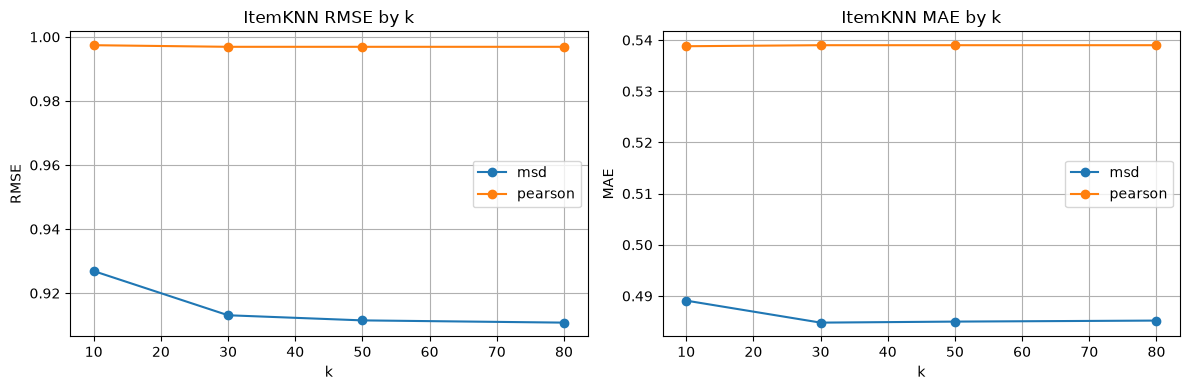

In [4]:
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))

for similarity, group in item_results.groupby("similarity"):
    group = group.sort_values("k_neighbors")
    axs[0].plot(group["k_neighbors"], group["RMSE"], marker="o", label=similarity)
    axs[1].plot(group["k_neighbors"], group["MAE"], marker="o", label=similarity)

axs[0].set_title("ItemKNN RMSE by k")
axs[0].set_xlabel("k")
axs[0].set_ylabel("RMSE")
axs[0].grid(True)
axs[0].legend()

axs[1].set_title("ItemKNN MAE by k")
axs[1].set_xlabel("k")
axs[1].set_ylabel("MAE")
axs[1].grid(True)
axs[1].legend()

plt.tight_layout()
plt.show()

## Best ItemKNN configuration

In [5]:
from tarea_01.experiments_item_funksvd import build_ranking_testset
from tarea_01.utils import calculate_metrics

best_row = item_results.sort_values("RMSE").iloc[0]
best_k = int(best_row["k_neighbors"])
best_similarity = best_row["similarity"]
model = item_models[(best_k, best_similarity)]

# La seed 42 no viene impuesta por el enunciado; se fija para reproducibilidad.
ranking_testset = build_ranking_testset(
    train_df=train_df,
    validation_df=test_df,
    n_negatives=100,
    seed=42,
)

metrics = calculate_metrics(
    model=model,
    testset=ranking_testset,
    k=10,
    threshold=4.0,
)
ranking_set_rmse = metrics.pop("RMSE")

pd.DataFrame(
    {
        "Item Based": {
            "k_neighbors": best_k,
            "similarity": best_similarity,
            "RMSE": best_row["RMSE"],
            "MAE": best_row["MAE"],
            "RankingSetRMSE": ranking_set_rmse,
            **metrics,
        }
    }
).T

,k_neighbors,similarity,RMSE,MAE,RankingSetRMSE,Recall@10,Precision@10,NDCG@10,MAP@10,Diversity,Novelty
Item Based,80,msd,0.9108,0.4852,4.5368,0.2321,0.0926,0.2709,0.2266,0.9868,13.3775
